# 02 — Análise Exploratória de Dados (EDA)

Este notebook analisa o dataset **SAML-D** (~9,5 milhões de transações) a partir do carregamento
oficial (`fraudradar.data.saml_d.load_csv`), investigando:
1. Período temporal e volume semanal;
2. Desbalanceamento extremo entre operações normais e lavagem de dinheiro;
3. Distribuição por tipologia (`typology`);
4. Meios de pagamento (`payment_type`);
5. Jurisdições (`sender_country` / `receiver_country`) e moedas;
6. Distribuição dos valores (`amount`) e conexões com o modelo e as regras de cenário.

> **Nota sobre uso do gabarito:** a tabela `ground_truth` é unida aqui apenas para diagnóstico
> exploratório. Em produção e na geração de scores, o modelo nunca lê o gabarito.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from fraudradar.config import ROOT_DIR
from fraudradar.data.saml_d import load_csv
from fraudradar.features.history import week_start

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

tx, gt = load_csv(ROOT_DIR / "data" / "SAML-D.csv")
df = tx.join(gt[["label", "typology"]])
df["week"] = week_start(df["occurred_at"])
start_d, end_d = df["occurred_at"].min().date(), df["occurred_at"].max().date()
print(f"Total de transações: {len(df):,} | Período: {start_d} a {end_d}")

Total de transações: 9,504,852 | Período: 2022-10-07 a 2023-08-23


## 1. Período temporal e volume semanal

As semanas do projeto são sempre ancoradas na **segunda-feira** (`week_start`), de outubro de 2022
a agosto de 2023 (~46 semanas).


Total de semanas: 47 | Média semanal: 202,231 transações


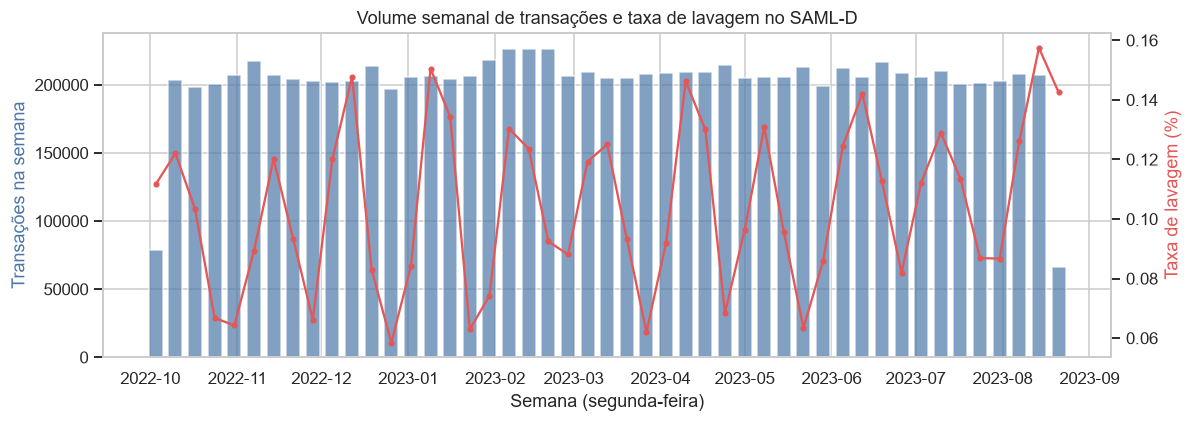

In [2]:
weekly = df.groupby("week").agg(total=("label", "size"), laundering=("label", "sum")).reset_index()
weekly["rate_pct"] = weekly["laundering"] / weekly["total"] * 100
print(f"Total de semanas: {len(weekly)} | Média semanal: {weekly['total'].mean():,.0f} transações")

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(weekly["week"], weekly["total"], width=5, color="#4C78A8", alpha=0.7, label="Transações")
ax1.set_ylabel("Transações na semana", color="#4C78A8")
ax1.set_xlabel("Semana (segunda-feira)")

ax2 = ax1.twinx()
ax2.plot(
    weekly["week"],
    weekly["rate_pct"],
    color="#E45756",
    marker="o",
    ms=3,
    label="Taxa de lavagem (%)",
)
ax2.set_ylabel("Taxa de lavagem (%)", color="#E45756")
ax2.grid(False)

plt.title("Volume semanal de transações e taxa de lavagem no SAML-D")
fig.tight_layout()
plt.show()

## 2. Desbalanceamento extremo das classes

Apenas **0,1039%** das operações representam lavagem de dinheiro (cerca de **1 caso suspeito para cada
962 normais**). Por isso, acurácia isolada é enganosa — um classificador trivial (`DummyClassifier`)
que marcasse tudo como normal teria **99,90%** de acurácia com **0%** de recall.


,Classe,Quantidade,Percentual (%)
0,Normal (0),9494979,99.8961
1,Lavagem (1),9873,0.1039


Razão normal : lavagem = 961.7 : 1


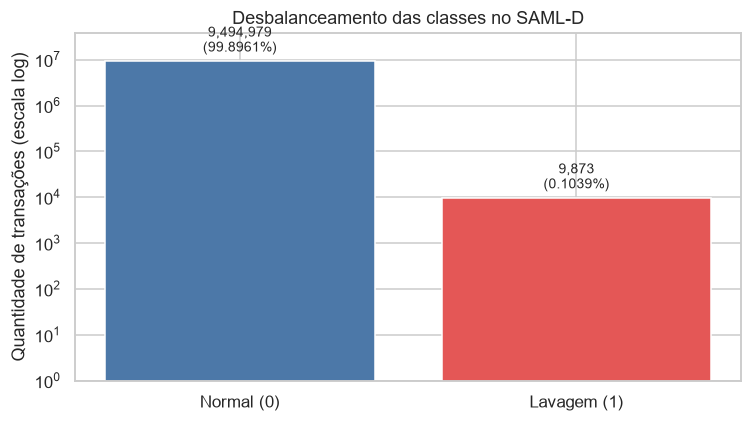

In [3]:
counts = df["label"].value_counts().sort_index()
n_normal, n_laund = int(counts.loc[0]), int(counts.loc[1])
total = len(df)
summary_cls = pd.DataFrame(
    {
        "Classe": ["Normal (0)", "Lavagem (1)"],
        "Quantidade": [n_normal, n_laund],
        "Percentual (%)": [n_normal / total * 100, n_laund / total * 100],
    }
)
display(summary_cls.round(4))
print(f"Razão normal : lavagem = {n_normal / n_laund:.1f} : 1")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(summary_cls["Classe"], summary_cls["Quantidade"], color=["#4C78A8", "#E45756"])
ax.set_yscale("log")
ax.set_ylabel("Quantidade de transações (escala log)")
ax.set_title("Desbalanceamento das classes no SAML-D")
for bar, qty, pct in zip(
    bars, summary_cls["Quantidade"], summary_cls["Percentual (%)"], strict=True
):
    ax.annotate(
        f"{qty:,}\n({pct:.4f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, qty),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
ax.set_ylim(1, n_normal * 4)
plt.tight_layout()
plt.show()

## 3. Distribuição por tipologia (`typology`)

O dataset possui 28 tipologias: 11 padrões normais e 17 tipologias de lavagem (estruturas em rede,
fracionamento, movimentação em espécie e mudança comportamental).


,typology,label,transactions
20,normal_small_fan_out,0,3477717
14,normal_fan_out,0,2302220
13,normal_fan_in,0,2104285
16,normal_group,0,528351
12,normal_cash_withdrawal,0,305031
11,normal_cash_deposits,0,223801
18,normal_periodical,0,210526
19,normal_plus_mutual,0,155041
17,normal_mutual,0,125335
15,normal_forward,0,42031


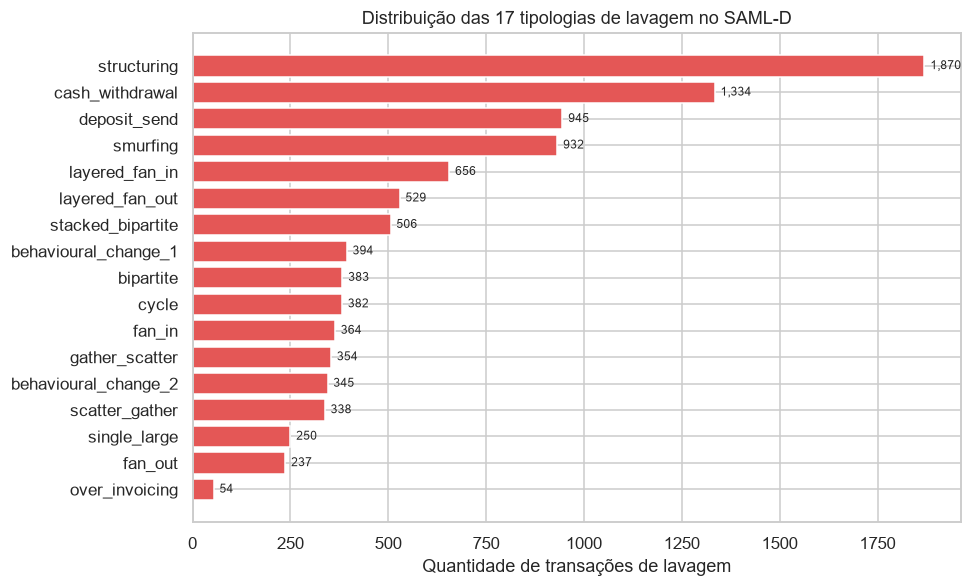

In [4]:
typ_summary = (
    df.groupby(["typology", "label"], observed=True)
    .size()
    .reset_index(name="transactions")
    .sort_values("transactions", ascending=False)
)
laund_typ = typ_summary[typ_summary["label"] == 1].sort_values("transactions", ascending=True)
display(typ_summary.head(15))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(laund_typ["typology"], laund_typ["transactions"], color="#E45756")
ax.set_xlabel("Quantidade de transações de lavagem")
ax.set_title("Distribuição das 17 tipologias de lavagem no SAML-D")
for i, v in enumerate(laund_typ["transactions"]):
    ax.text(v + 15, i, f"{v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

## 4. Distribuição por meio de pagamento (`payment_type`)

Meios em espécie (`Cash Deposit` e `Cash Withdrawal`) e transferências internacionais
(`Cross-border`) concentram taxas relativas de lavagem mais elevadas que cartões, cheques e ACH.


,payment_type,total,laundering,rate_pct
0,Cash Deposit,225206,1405,0.6239
1,Cash Withdrawal,300477,1334,0.4440
2,Cross-border,933931,2628,0.2814
3,ACH,2008807,1159,0.0577
4,Credit card,2012909,1136,0.0564
5,Debit card,2012103,1124,0.0559
6,Cheque,2011419,1087,0.0540


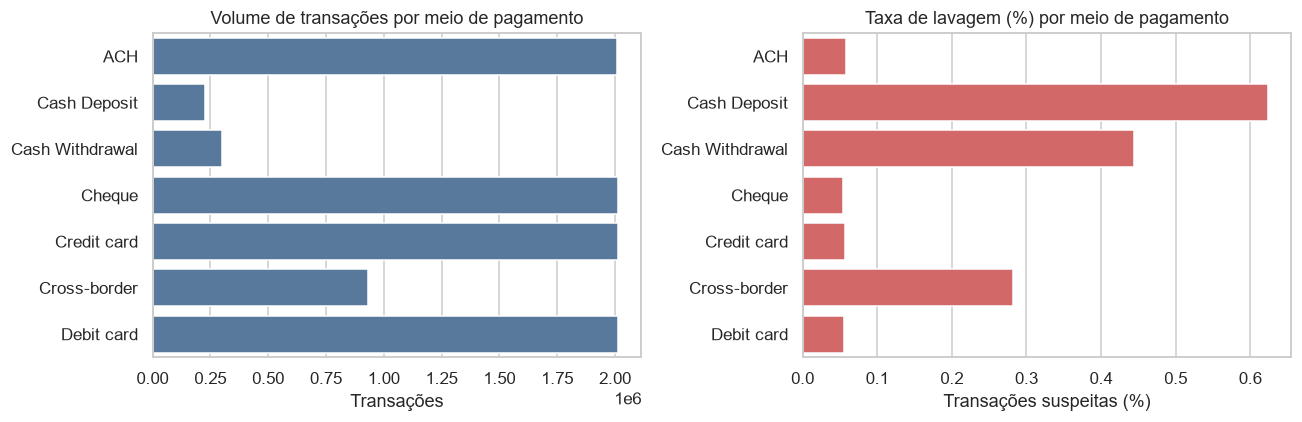

In [5]:
by_pay = (
    df.groupby("payment_type", observed=True)
    .agg(total=("label", "size"), laundering=("label", "sum"))
    .assign(rate_pct=lambda d: d["laundering"] / d["total"] * 100)
    .sort_values("rate_pct", ascending=False)
    .reset_index()
)
display(by_pay.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=by_pay, x="total", y="payment_type", color="#4C78A8", ax=axes[0])
axes[0].set_title("Volume de transações por meio de pagamento")
axes[0].set_xlabel("Transações")
axes[0].set_ylabel("")

sns.barplot(data=by_pay, x="rate_pct", y="payment_type", color="#E45756", ax=axes[1])
axes[1].set_title("Taxa de lavagem (%) por meio de pagamento")
axes[1].set_xlabel("Transações suspeitas (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 5. Jurisdições (`sender_country` / `receiver_country`) e moedas

Embora o maior volume esteja no Reino Unido (`UK`), a incidência relativa de lavagem é maior em
remessas internacionais envolvendo jurisdições de maior risco (como `Nigeria`, `Albania`, `Turkey`,
`Pakistan`, `UAE` e `Morocco`). Ao mesmo tempo, o `docs/model.md` documenta por que país, moeda e
hora são **excluídos do LightGBM** (`EXCLUDED_FEATURES`): no gerador sintético, essas colunas criam
atalhos artificiais e viés regional de falso positivo; em vez disso, o risco geográfico é tratado de
forma transparente pelas regras de cenário em `db/rules/` (`R-003`).


,receiver_country,total,laundering,rate_pct
0,Nigeria,38272,251,0.6558
1,Morocco,38704,253,0.6537
2,Albania,38783,235,0.6059
3,UAE,35897,195,0.5432
4,Mexico,38385,197,0.5132
5,Turkey,35586,177,0.4974
6,Pakistan,38980,169,0.4336
7,Netherlands,37314,148,0.3966
8,Austria,38844,154,0.3965
9,India,36936,137,0.3709


Transações transfronteiriças: 9.83% | taxa de lavagem: 0.3259% (vs domésticas: 0.0797%)
Divergência de moeda: 11.42% | taxa de lavagem: 0.3368%


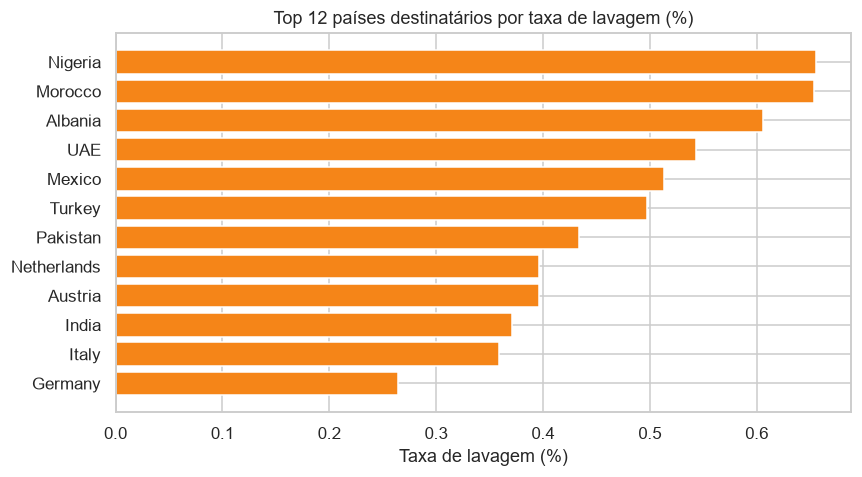

In [6]:
by_rcountry = (
    df.groupby("receiver_country", observed=True)
    .agg(total=("label", "size"), laundering=("label", "sum"))
    .assign(rate_pct=lambda d: d["laundering"] / d["total"] * 100)
    .sort_values("rate_pct", ascending=False)
    .reset_index()
)
display(by_rcountry.head(10).round(4))

cross_border = df["sender_country"].astype(str) != df["receiver_country"].astype(str)
currency_mismatch = df["payment_currency"].astype(str) != df["received_currency"].astype(str)
cb_rate = df.loc[cross_border, "label"].mean()
dom_rate = df.loc[~cross_border, "label"].mean()
print(
    f"Transações transfronteiriças: {cross_border.mean():.2%} | "
    f"taxa de lavagem: {cb_rate:.4%} (vs domésticas: {dom_rate:.4%})"
)
mm_rate = df.loc[currency_mismatch, "label"].mean()
print(f"Divergência de moeda: {currency_mismatch.mean():.2%} | taxa de lavagem: {mm_rate:.4%}")

top_countries = by_rcountry.head(12).sort_values("rate_pct", ascending=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_countries["receiver_country"].astype(str), top_countries["rate_pct"], color="#F58518")
ax.set_xlabel("Taxa de lavagem (%)")
ax.set_title("Top 12 países destinatários por taxa de lavagem (%)")
plt.tight_layout()
plt.show()

## 6. Distribuição dos valores (`amount`)

Os valores individuais apresentam cauda longa (assimetria à direita). Aplicando `log1p(amount)`,
observa-se separação parcial de faixas entre operações normais e suspeitas — especialmente quando
combinada ao meio de pagamento.


,count,mean,median,p90,p99,max
label,,,,,,
Normal (0),9494979,8729.88,6114.63,16558.43,44938.16,999962.19
Lavagem (1),9873,40587.67,5322.79,21197.62,419540.08,12618498.40


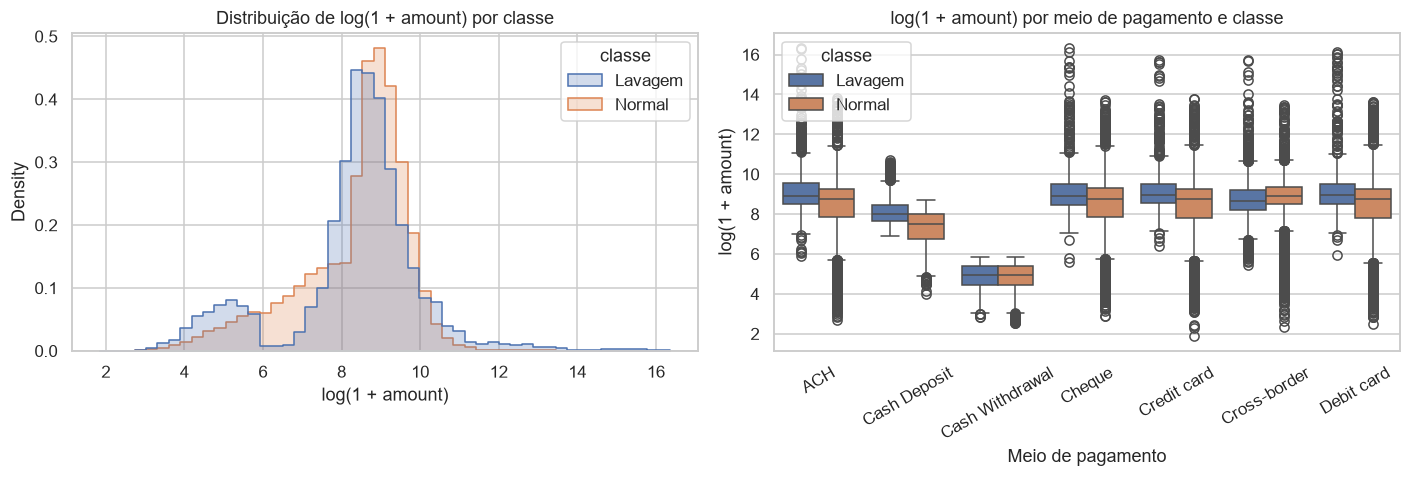

In [7]:
amount_stats = (
    df.groupby("label")["amount"]
    .agg(
        count="size",
        mean="mean",
        median="median",
        p90=lambda s: s.quantile(0.90),
        p99=lambda s: s.quantile(0.99),
        max="max",
    )
    .rename(index={0: "Normal (0)", 1: "Lavagem (1)"})
)
display(amount_stats.round(2))

# Amostra balanceada para visualização ágil: todas as positivas + 100 mil normais
pos = df[df["label"] == 1]
neg = df[df["label"] == 0].sample(100_000, random_state=42)
sample = pd.concat([pos, neg], ignore_index=True)
sample["classe"] = sample["label"].map({0: "Normal", 1: "Lavagem"})
sample["amount_log"] = np.log1p(sample["amount"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(
    data=sample,
    x="amount_log",
    hue="classe",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0],
)
axes[0].set_title("Distribuição de log(1 + amount) por classe")
axes[0].set_xlabel("log(1 + amount)")

sns.boxplot(data=sample, x="payment_type", y="amount_log", hue="classe", ax=axes[1])
axes[1].set_title("log(1 + amount) por meio de pagamento e classe")
axes[1].set_xlabel("Meio de pagamento")
axes[1].set_ylabel("log(1 + amount)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 7. Síntese para o modelo e as regras de cenário

- O extremo desbalanceamento (~0,10%) exige ordenação por **PR-AUC** e fila semanal limitada por
  conta (`alerts` com `queue_size = 300`), evitando inundar o analista com falsos positivos.
- Os padrões observados fundamentam as duas camadas complementares do FraudRadar:
  1. **Regras determinísticas (`db/rules/R-001` a `R-005`):** fracionamento de depósitos em
     espécie, fan-out/fan-in elevado, jurisdições de risco, salto brusco de volume e concentração em
     espécie;
  2. **Modelo LightGBM (`notebooks/03_modelo.ipynb`):** 21 variáveis históricas sem atalhos
     geográficos/horários e com tratamento explícito do `CASH_ACCOUNT = -1`.
